# Gas Analytics

German gas storage fill levels (source: Bundesnetzagentur / AGSI+).

In [2]:
from gasstoragelevel.data_retrieval import fetch_gas_storage_levels

df = fetch_gas_storage_levels()
df.tail()

,date,gas_year,fill_level_pct
582,2026-11-04,04/2026-03/2027,60.25
583,2026-11-05,04/2026-03/2027,59.97
584,2026-11-06,04/2026-03/2027,59.54
585,2026-11-07,04/2026-03/2027,59.21
586,2026-11-08,04/2026-03/2027,58.95


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 587 entries, 0 to 586
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   date            587 non-null    datetime64[us]
 1   gas_year        587 non-null    str           
 2   fill_level_pct  587 non-null    float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 13.9 KB


## Gas storage fill level by gas year

Each line is one gas year (April–March), so the years can be compared day by day.

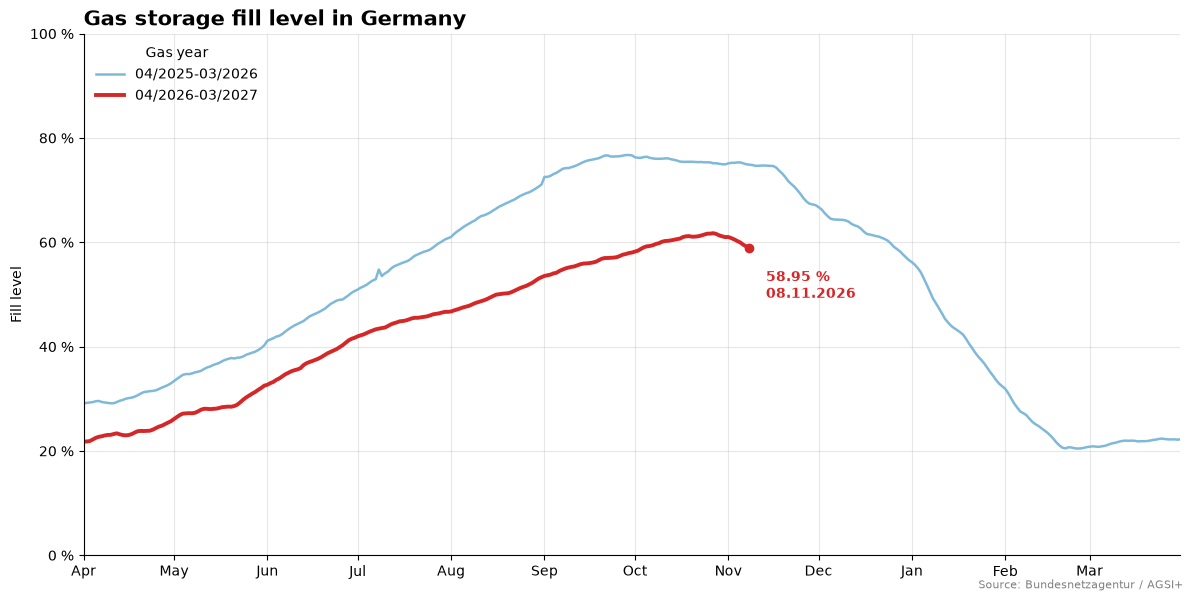

In [4]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

# Map every date onto a common gas-year axis (reference year 2000/2001, a leap year).
start_year = df["date"].dt.year - (df["date"].dt.month < 4)
gas_year_start = pd.to_datetime(start_year.astype(str) + "-04-01")
plot_df = df.assign(plot_date=pd.Timestamp("2000-04-01") + (df["date"] - gas_year_start))

latest = df.iloc[-1]
gas_years = sorted(plot_df["gas_year"].unique())
colors = plt.cm.Blues([0.45 + 0.5 * i / max(len(gas_years) - 1, 1) for i in range(len(gas_years))])

fig, ax = plt.subplots(figsize=(12, 6))
for gas_year, color in zip(gas_years, colors, strict=True):
    data = plot_df[plot_df["gas_year"] == gas_year]
    is_current = gas_year == latest["gas_year"]
    ax.plot(
        data["plot_date"],
        data["fill_level_pct"],
        label=gas_year,
        color="#d62728" if is_current else color,
        linewidth=2.8 if is_current else 1.8,
    )

current = plot_df.iloc[-1]
ax.scatter(current["plot_date"], current["fill_level_pct"], color="#d62728", zorder=5)
ax.annotate(
    f"{latest['fill_level_pct']:.2f} %\n{latest['date']:%d.%m.%Y}",
    xy=(current["plot_date"], current["fill_level_pct"]),
    xytext=(12, -36),
    textcoords="offset points",
    fontsize=10,
    fontweight="bold",
    color="#d62728",
)

ax.set_ylim(0, 100)
ax.set_xlim(pd.Timestamp("2000-04-01"), pd.Timestamp("2001-03-31"))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0f} %")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Gas storage fill level in Germany", fontsize=15, fontweight="bold", loc="left")
ax.set_ylabel("Fill level")
ax.legend(title="Gas year", frameon=False, loc="upper left")
fig.text(0.99, 0.01, "Source: Bundesnetzagentur / AGSI+", ha="right", fontsize=8, color="gray")
fig.tight_layout()
plt.show()